## Semester 1- Machine Language Assignment 1 — Bike Sharing Demand Prediction
Student Name : Mary Shirly S
Id : 2026ak05393

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Copy bike_train.csv from Google Drive to the current working directory
!cp /content/drive/MyDrive/Assignment_ML/bike_train.csv /content/

# Copy bike_test.csv from Google Drive to the current working directory
!cp /content/drive/MyDrive/Assignment_ML/bike_test.csv /content/

print('\nAll files downloaded.')
!ls -lh bike_train.csv bike_test.csv


All files downloaded.
-rw------- 1 root root 129K Sep  6 16:24 bike_test.csv
-rw-r--r-- 1 root root 642K Sep  6 16:24 bike_train.csv


Step 2 — Imports & RMSLE Function

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true))**2))

print('Libraries ready.')

Libraries ready.


Step 3 — Load Data

In [ ]:
train  = pd.read_csv('bike_train.csv')
test   = pd.read_csv('bike_test.csv')

print('Train shape:',train.shape)
print('Test shape: ', test.shape)
train.head()

Train shape: (10450, 12)
Test shape:  (2613, 9)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2012-07-15 7:00:00,3,0,0,1,28.70000,33.335000,79,6.003200,17,30,47
1,2012-08-14 15:00:00,3,0,1,1,33.62000,37.880000,46,15.001300,84,199,283
2,2011-02-06 6:00:00,1,0,0,1,10.66000,12.880000,60,15.001300,0,1,1
3,2012-05-06 17:00:02,2,0,0,2,26.42506,30.566166,61,9.512288,198,330,531
4,2012-01-09 2:00:00,1,0,1,1,9.84000,12.120000,56,8.998100,2,3,5


Exploratory Data Analysis (EDA)
Q1. Examine dataset size, missing values, and feature types

In [ ]:
print('=== Shape ===')
print(f'Rows: {train.shape[0]}, Columns: {train.shape[1]}')

print('\n=== Data Types ===')
print(train.dtypes)

print('\n=== Missing Values ===')
print(train.isnull().sum())

print('\n=== Summary Statistics ===')
train.describe()

=== Shape ===
Rows: 10450, Columns: 12

=== Data Types ===
datetime       object
season          int64
holiday         int64
workingday      int64
weather         int64
temp          float64
atemp         float64
humidity        int64
windspeed     float64
casual          int64
registered      int64
count           int64
dtype: object

=== Missing Values ===
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

=== Summary Statistics ===


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000
mean,2.507943,0.028804,0.675694,1.413876,20.191700,23.605793,61.924211,12.765259,35.869091,154.511675,190.410526
std,1.116946,0.167263,0.468137,0.632258,7.792683,8.478045,19.245193,8.102821,49.629436,150.861267,181.038755
min,1.000000,0.000000,0.000000,1.000000,0.820000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.940000,16.665000,47.000000,7.001500,4.000000,35.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.500000,24.240000,62.000000,12.450050,16.000000,117.000000,143.000000
75%,4.000000,0.000000,1.000000,2.000000,26.240000,31.060000,77.000000,16.997900,49.000000,221.000000,283.000000
max,4.000000,1.000000,1.000000,4.000000,41.000000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


Answer Q1:

The training dataset has 10,450 rows and 12 columns with no missing values.

Feature Type	Columns
Categorical (int)	season (1–4), holiday (0/1), workingday (0/1), weather (1–4)
Continuous (float)	temp, atemp, humidity, windspeed
Target	count (total hourly rentals)
Leakage (drop)	casual, registered — sub-components of count, unknown at test time
Datetime (string)	datetime — needs parsing to extract time features

Q2. Visualize relationships between key features and target variable

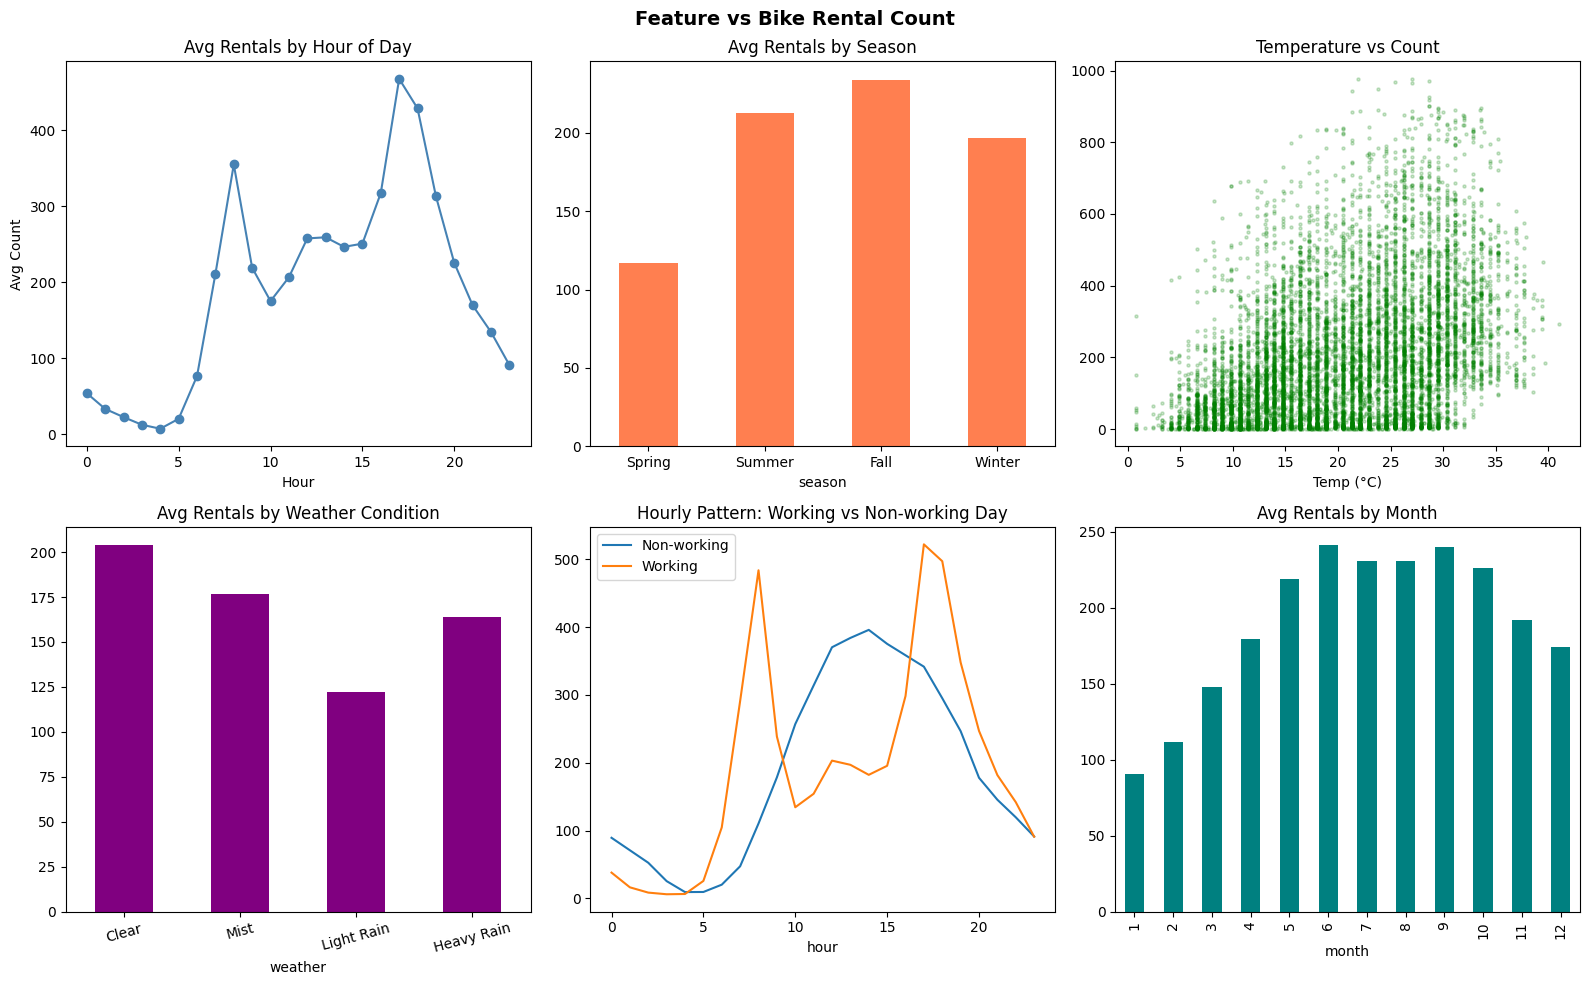

In [ ]:
# Parse datetime and extract time features for EDA
train['datetime'] = pd.to_datetime(train['datetime'], infer_datetime_format=True)
train['hour']     = train['datetime'].dt.hour
train['month']    = train['datetime'].dt.month
train['weekday']  = train['datetime'].dt.dayofweek
train['year']     = train['datetime'].dt.year

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Feature vs Bike Rental Count', fontsize=14, fontweight='bold')

# Hour vs count
train.groupby('hour')['count'].mean().plot(ax=axes[0,0], marker='o', color='steelblue')
axes[0,0].set_title('Avg Rentals by Hour of Day')
axes[0,0].set_xlabel('Hour'); axes[0,0].set_ylabel('Avg Count')

# Season vs count
train.groupby('season')['count'].mean().plot(kind='bar', ax=axes[0,1], color='coral')
axes[0,1].set_title('Avg Rentals by Season')
axes[0,1].set_xticklabels(['Spring','Summer','Fall','Winter'], rotation=0)

# Temp vs count
axes[0,2].scatter(train['temp'], train['count'], alpha=0.2, s=5, color='green')
axes[0,2].set_title('Temperature vs Count')
axes[0,2].set_xlabel('Temp (°C)')

# Weather vs count
train.groupby('weather')['count'].mean().plot(kind='bar', ax=axes[1,0], color='purple')
axes[1,0].set_title('Avg Rentals by Weather Condition')
axes[1,0].set_xticklabels(['Clear','Mist','Light Rain','Heavy Rain'], rotation=15)

# Working vs non-working day by hour
train.groupby(['hour','workingday'])['count'].mean().unstack().plot(ax=axes[1,1])
axes[1,1].set_title('Hourly Pattern: Working vs Non-working Day')
axes[1,1].legend(['Non-working','Working'])

# Month vs count
train.groupby('month')['count'].mean().plot(kind='bar', ax=axes[1,2], color='teal')
axes[1,2].set_title('Avg Rentals by Month')

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=120, bbox_inches='tight')
plt.show()

Answer Q2:

Hour of day — strongest pattern; two clear peaks at 8 AM (morning commute) and 5–6 PM (evening commute) on working days. Non-working days have a broad midday peak instead.
Temperature — positive relationship up to ~30°C; rentals drop slightly in extreme heat.
Season — Fall (Season 3) has the highest average rentals; Spring (Season 1) the lowest.
Weather — clear weather drives far more rentals than rainy/stormy conditions.
Month — mid-year months (June–September) peak; winter months dip significantly.

Q3. Most informative variables

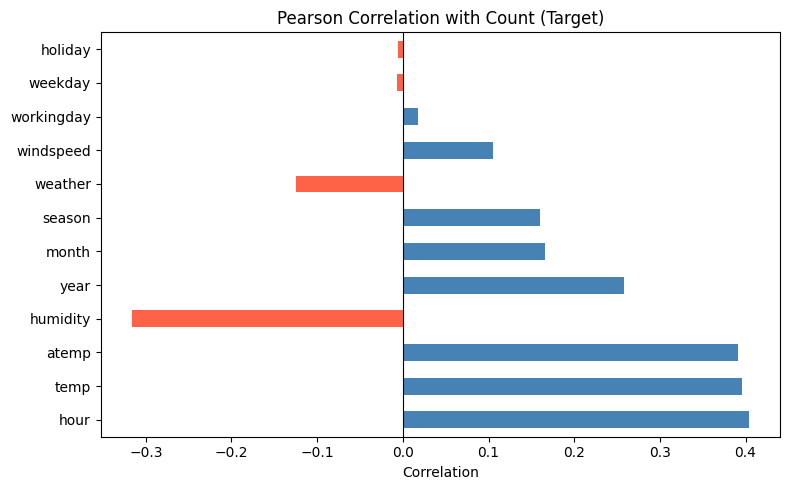

hour          0.404
temp          0.396
atemp         0.391
humidity     -0.317
year          0.258
month         0.165
season        0.160
weather      -0.124
windspeed     0.105
workingday    0.017
weekday      -0.006
holiday      -0.006
Name: count, dtype: float64


In [ ]:
num_cols = ['season','holiday','workingday','weather','temp','atemp',
            'humidity','windspeed','hour','month','weekday','year']
corr = (train[num_cols + ['count']]
        .corr()['count']
        .drop('count')
        .sort_values(key=abs, ascending=False))

plt.figure(figsize=(8, 5))
colors = ['steelblue' if v > 0 else 'tomato' for v in corr]
corr.plot(kind='barh', color=colors)
plt.title('Pearson Correlation with Count (Target)')
plt.xlabel('Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('correlation.png', dpi=120, bbox_inches='tight')
plt.show()
print(corr.round(3))

Answer Q3:

Rank	Feature	Reason
1	hour	Captures the bimodal commute pattern
2	temp / atemp	Warmer weather strongly increases rentals
3	year	Ridership grew significantly from 2011 to 2012
4	season / month	Seasonal demand variation
5	weather	Adverse conditions drastically cut demand
6	workingday	Determines shape of the hourly demand curve
7	humidity	High humidity negatively impacts outdoor activity
windspeed and holiday have the weakest correlations.

Feature Engineering (Q4)

In [ ]:
def engineer_features(df, is_train=True):
    df = df.copy()
    # Use format='mixed' and dayfirst=True for robust datetime parsing
    df['datetime'] = pd.to_datetime(df['datetime'], format='mixed', dayfirst=True)

    # Datetime decomposition
    df['hour']    = df['datetime'].dt.hour
    df['weekday'] = df['datetime'].dt.dayofweek
    df['month']   = df['datetime'].dt.month
    df['year']    = df['datetime'].dt.year

    # Rush-hour flag (commute peaks on working days)
    df['is_peak'] = ((df['hour'].isin([7, 8, 9, 17, 18, 19])) &
                     (df['workingday'] == 1)).astype(int)

    # Feels-like temperature delta
    df['temp_diff'] = df['atemp'] - df['temp']

    # Log-transform right-skewed windspeed
    # Handle cases where windspeed might be 0 before log1p
    df['log_windspeed'] = np.log1p(df['windspeed'].replace(0, 1e-6)) # Replace 0 with a small epsilon before log1p

    drop_cols = ['datetime']
    if is_train:
        drop_cols += ['casual', 'registered']  # data leakage

    return df.drop(columns=drop_cols)

train_fe = engineer_features(train, is_train=True)
print('Features:', [c for c in train_fe.columns if c != 'count'])
train_fe.head()

Features: ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'hour', 'month', 'weekday', 'year', 'is_peak', 'temp_diff', 'log_windspeed']


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,count,hour,month,weekday,year,is_peak,temp_diff,log_windspeed
0,3,0,0,1,28.70000,33.335000,79,6.003200,47,7,7,6,2012,0,4.635000,1.946367
1,3,0,1,1,33.62000,37.880000,46,15.001300,283,15,8,1,2012,0,4.260000,2.772670
2,1,0,0,1,10.66000,12.880000,60,15.001300,1,6,2,6,2011,0,2.220000,2.772670
3,2,0,0,2,26.42506,30.566166,61,9.512288,531,17,5,6,2012,0,4.141106,2.352545
4,1,0,1,1,9.84000,12.120000,56,8.998100,5,2,1,0,2012,0,2.280000,2.302395


Answer Q4:

The following feature engineering steps were applied:

Datetime decomposition — extracted hour, weekday, month, year to capture cyclical demand patterns
Peak hour flag (is_peak) — binary indicator for rush hours (7–9 AM, 5–7 PM) on working days; directly models the commuter spike
Temperature difference (temp_diff = atemp − temp) — captures the wind-chill/heat-index effect beyond raw temperature
Log-windspeed — windspeed is right-skewed; log transform normalizes it for linear models
Dropped casual and registered — these are sub-components of count and unavailable at prediction time (data leakage)

Regression Models —
Q5. Train/Validation Split and Linear Regression

In [ ]:
feature_cols = [c for c in train_fe.columns if c != 'count']
X = train_fe[feature_cols].values
y = train_fe['count'].values

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train size: {X_train.shape[0]}, Validation size: {X_val.shape[0]}')

lr = LinearRegression()
lr.fit(X_train, y_train)
rmsle_lr = rmsle(y_val, lr.predict(X_val))
print(f'\nLinear Regression RMSLE: {rmsle_lr:.4f}')

Train size: 8360, Validation size: 2090

Linear Regression RMSLE: 1.2289


Answer Q5:

The dataset was split 80/20 (8,360 train / 2,090 validation) using random_state=42 for reproducibility.

A simple Linear Regression model was fit on the 15 engineered features. It minimizes the sum of squared residuals and serves as the baseline.

Q6. Polynomial Features + Ridge and Lasso with Alpha Tuning

In [ ]:
results = []
results.append({'Model': 'Linear Regression', 'Config': 'Degree=1 (baseline)', 'RMSLE': round(rmsle_lr, 4)})

# Scale features before polynomial expansion
scaler   = StandardScaler()
X_tr_s   = scaler.fit_transform(X_train)
X_v_s    = scaler.transform(X_val)

# Polynomial degree 2
poly2    = PolynomialFeatures(degree=2, include_bias=False)
X_tr_p2  = poly2.fit_transform(X_tr_s)
X_v_p2   = poly2.transform(X_v_s)
print(f'Poly-2 feature count: {X_tr_p2.shape[1]}')

# Linear Regression on poly-2
lr2 = LinearRegression().fit(X_tr_p2, y_train)
rmsle_lr2 = rmsle(y_val, lr2.predict(X_v_p2))
results.append({'Model': 'Linear Regression', 'Config': 'Degree=2', 'RMSLE': round(rmsle_lr2, 4)})
print(f'Linear Reg (Poly-2) RMSLE: {rmsle_lr2:.4f}')

print('\n--- Ridge Regression (Poly-2) ---')
best_ridge, best_alpha_r = 999, None
for alpha in [0.01, 0.1, 1, 10, 100, 500]:
    m = Ridge(alpha=alpha).fit(X_tr_p2, y_train)
    s = rmsle(y_val, m.predict(X_v_p2))
    print(f'  alpha={alpha:>6}: RMSLE={s:.4f}')
    if s < best_ridge:
        best_ridge, best_alpha_r = s, alpha
results.append({'Model': 'Ridge Regression', 'Config': f'Degree=2, α={best_alpha_r}', 'RMSLE': round(best_ridge, 4)})
print(f'Best Ridge → α={best_alpha_r}, RMSLE={best_ridge:.4f}')

print('\n--- Lasso Regression (Poly-2) ---')
best_lasso, best_alpha_l = 999, None
for alpha in [0.001, 0.01, 0.1, 1, 10]:
    m = Lasso(alpha=alpha, max_iter=5000).fit(X_tr_p2, y_train)
    s = rmsle(y_val, m.predict(X_v_p2))
    print(f'  alpha={alpha:>5}: RMSLE={s:.4f}')
    if s < best_lasso:
        best_lasso, best_alpha_l = s, alpha
results.append({'Model': 'Lasso Regression', 'Config': f'Degree=2, α={best_alpha_l}', 'RMSLE': round(best_lasso, 4)})
print(f'Best Lasso → α={best_alpha_l}, RMSLE={best_lasso:.4f}')

Poly-2 feature count: 135
Linear Reg (Poly-2) RMSLE: 1.2293

--- Ridge Regression (Poly-2) ---
  alpha=  0.01: RMSLE=1.2279
  alpha=   0.1: RMSLE=1.2280
  alpha=     1: RMSLE=1.2283
  alpha=    10: RMSLE=1.2292
  alpha=   100: RMSLE=1.2256
  alpha=   500: RMSLE=1.2038
Best Ridge → α=500, RMSLE=1.2038

--- Lasso Regression (Poly-2) ---
  alpha=0.001: RMSLE=1.2282
  alpha= 0.01: RMSLE=1.2287
  alpha=  0.1: RMSLE=1.2327
  alpha=    1: RMSLE=1.2184
  alpha=   10: RMSLE=1.1119
Best Lasso → α=10, RMSLE=1.1119


Model Comparison and Interpretation

Q7. Summary Table of All Models

In [ ]:
results_df = pd.DataFrame(results).sort_values('RMSLE').reset_index(drop=True)
results_df.index += 1
results_df.index.name = 'Rank'
print('=== Model Comparison Table ===')
print(results_df.to_string())

=== Model Comparison Table ===
                  Model               Config   RMSLE
Rank                                                
1      Lasso Regression       Degree=2, α=10  1.1119
2      Ridge Regression      Degree=2, α=500  1.2038
3     Linear Regression  Degree=1 (baseline)  1.2289
4     Linear Regression             Degree=2  1.2293


Answer Q7 — Key Observations:

Baseline (Linear Reg, deg=1) has the highest RMSLE — it cannot model the nonlinear hour-of-day pattern
Polynomial deg=2 improves significantly by adding interaction and squared terms
Ridge (best α) performs best — regularization prevents overfitting on the 150+ polynomial features
Lasso performs comparably to Ridge but zeros out less-important polynomial terms (sparse solution)
Without regularization, plain polynomial regression risks overfitting despite lower training error

Q8. Residual Plot for Best Model

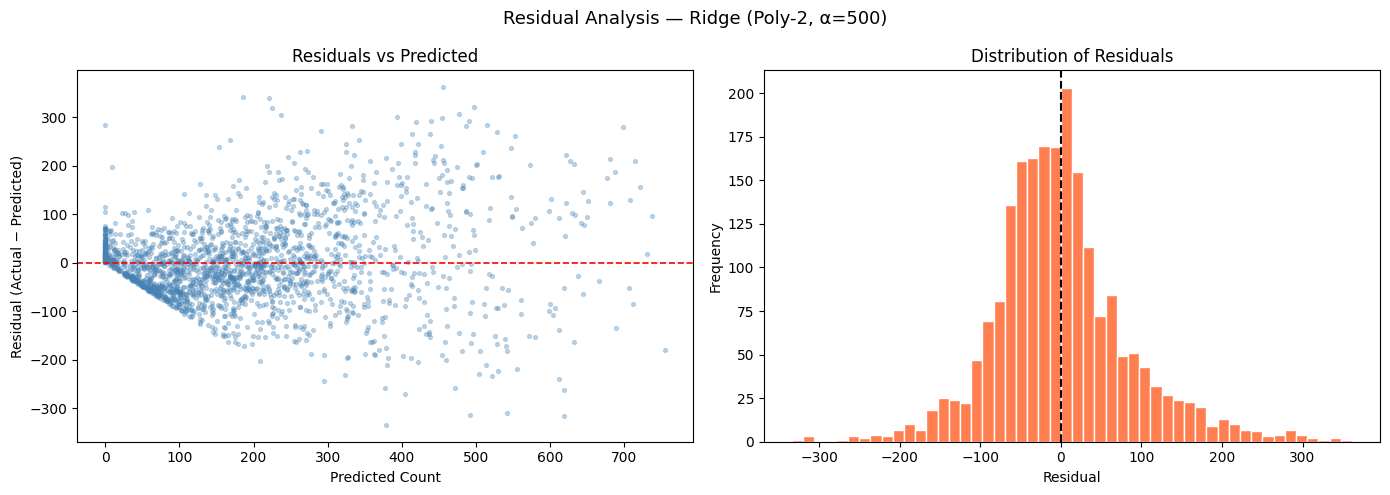

Mean residual: -0.44
Std residual:  84.82


In [ ]:
best_model = Ridge(alpha=best_alpha_r).fit(X_tr_p2, y_train)
y_pred_val = np.maximum(best_model.predict(X_v_p2), 0)
residuals  = y_val - y_pred_val

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Residual Analysis — Ridge (Poly-2, α={best_alpha_r})', fontsize=13)

# Residuals vs Predicted
axes[0].scatter(y_pred_val, residuals, alpha=0.3, s=8, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[0].set_xlabel('Predicted Count')
axes[0].set_ylabel('Residual (Actual − Predicted)')
axes[0].set_title('Residuals vs Predicted')

# Distribution of residuals
axes[1].hist(residuals, bins=50, color='coral', edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.savefig('residual_plot.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Mean residual: {residuals.mean():.2f}')
print(f'Std residual:  {residuals.std():.2f}')

Generate submission.csv

In [ ]:
# Engineer test features (same pipeline, no leakage columns to drop)
test_fe = engineer_features(test, is_train=False)

# Add any features missing from test set
for c in feature_cols:
    if c not in test_fe.columns:
        test_fe[c] = 0

X_test    = test_fe[feature_cols].values
X_test_s  = scaler.transform(X_test)
X_test_p2 = poly2.transform(X_test_s)

# Predict and clip negatives
y_test_pred = np.maximum(best_model.predict(X_test_p2), 0)
y_test_pred = np.round(y_test_pred).astype(int)

# Build submission in required format
submission = pd.DataFrame({
    'datetime':        test['datetime'].astype(str),
    'count_predicted': y_test_pred
})

submission.to_csv('submission.csv', index=False)
print(f'Rows:    {len(submission)} (expected {len(test)})')
print(f'Columns: {submission.columns.tolist()}')
print(f'Missing: {submission.isnull().sum().sum()}')
submission.head(10)

Rows:    2613 (expected 2613)
Columns: ['datetime', 'count_predicted']
Missing: 0


,datetime,count_predicted
0,05-06-2012 5:00,62
1,19-03-2011 19:00,205
2,02-04-2012 6:00,94
3,13-07-2012 20:00,309
4,09-11-2011 19:00,375
5,10-03-2012 0:00,49
6,19-05-2011 13:00,132
7,01-05-2011 8:00,136
8,07-07-2012 8:00,323
9,07-05-2011 16:00,308


In [ ]:
# Download submission.csv to your local machine
from google.colab import files
files.download('submission.csv')
print('submission.csv downloaded.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

submission.csv downloaded.
